# 01 · Exploring the raw logs
What the HDFS and BGL logs look like, how imbalanced they are, and how anomalies are distributed over time.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PARSED_DIR, RAW_DIR, RESULTS_DIR, SEQUENCES_DIR

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#888",
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_colwidth", 120)

## Raw lines

In [2]:
from src.parsing.parse_logs import find_raw_log
for ds in ("hdfs", "bgl"):
    with open(find_raw_log(ds), encoding="utf-8", errors="replace") as f:
        print(ds.upper()); [print("  ", next(f).rstrip()[:160]) for _ in range(4)]

HDFS
   081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010
   081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.jar. blk_-1608999687919862906
   081109 203519 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.10.6:50010
   081109 203519 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250.14.224:50010
BGL
   - 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.363779 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected
   - 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.527847 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected
   - 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.675872 R02-M1-N0-C:J12-U11 RAS

## Sessions and windows

In [3]:
sessions = {ds: pd.read_parquet(SEQUENCES_DIR / f"{ds}_sessions.parquet") for ds in ("hdfs", "bgl")}
pd.DataFrame({ds: {"groups": len(s), "anomalous": int(s.label.sum()), "anomaly rate": f"{s.label.mean():.2%}",
                   "median events": s.n_events.median(), "max events": s.n_events.max()}
              for ds, s in sessions.items()})

,hdfs,bgl
groups,575061,3607
anomalous,16838,665
anomaly rate,2.93%,18.44%
median events,19.0,49.0
max events,298,152929


Anomalous HDFS sessions are not simply longer or shorter: lengths overlap heavily, so length alone cannot separate them.

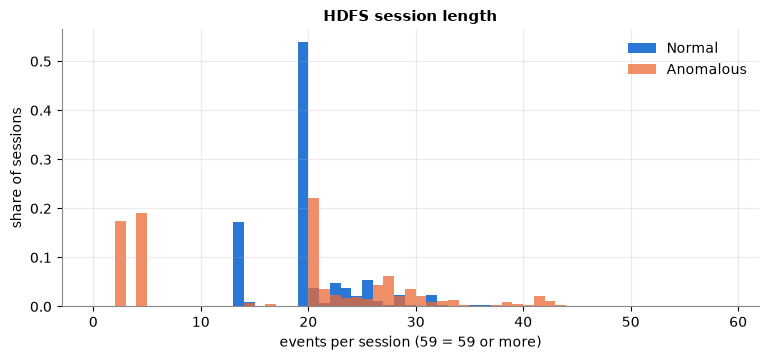

In [4]:
s = sessions["hdfs"]
bins = np.arange(0, 60, 1)
fig, ax = plt.subplots()
ax.hist(s.n_events[s.label == 0].clip(upper=59), bins=bins, color=BLUE, density=True, label="Normal")
ax.hist(s.n_events[s.label == 1].clip(upper=59), bins=bins, color=ORANGE, density=True, alpha=0.75, label="Anomalous")
ax.set(title="HDFS session length", xlabel="events per session (59 = 59 or more)", ylabel="share of sessions")
ax.legend(frameon=False); plt.show()

## Anomalies over time
BGL alerts arrive in bursts, which is why a random split would leak: neighbouring windows from the same burst would land in both train and test.

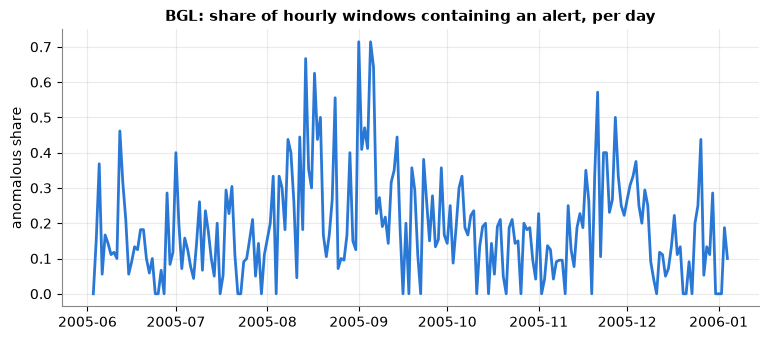

In [5]:
b = sessions["bgl"].assign(day=lambda d: pd.to_datetime(d.start_time, unit="s").dt.floor("D"))
daily = b.groupby("day").label.mean()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color=BLUE, lw=2)
ax.set(title="BGL: share of hourly windows containing an alert, per day", ylabel="anomalous share"); plt.show()

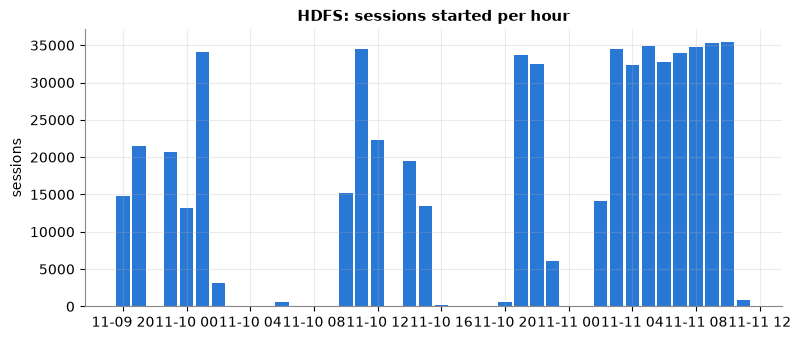

In [6]:
h = sessions["hdfs"].assign(hour=lambda d: pd.to_datetime(d.start_time, unit="s").dt.floor("h"))
hourly = h.groupby("hour").size()
fig, ax = plt.subplots()
ax.bar(hourly.index, hourly.values, width=0.035, color=BLUE)
ax.set(title="HDFS: sessions started per hour", ylabel="sessions"); plt.show()

HDFS block creation is bursty: the last 20% of sessions all start in the final ~2.5 hours of the log. Those sessions are cut off by the end of the file, which matters for evaluation (see notebook 05).